In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style for clean, publication-ready charts
sns.set_theme(style="whitegrid")

# Load your dataset (replace with your actual file path/name)
df = pd.read_csv('football_test_data.csv')

# Verify the data loaded correctly
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (8740, 90)


,FTR,HS,AS,HST,AST,HF,AF,HC,AC,HY,...,BFDA,BMGMH,BMGMD,BMGMA,BVH,BVD,BVA,CLH,CLD,CLA
0,H,11,13,5,7,8,15,6,9,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,H,10,15,5,7,20,27,1,4,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,H,25,8,13,5,8,14,6,2,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,H,17,8,9,5,18,16,7,6,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,D,12,13,7,10,27,15,2,7,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Lower League Counts:
 H    16298
A    11306
D    10220
Name: FTR, dtype: int64

Lower League Percentages:
 H    43.09
A    29.89
D    27.02
Name: FTR, dtype: float64


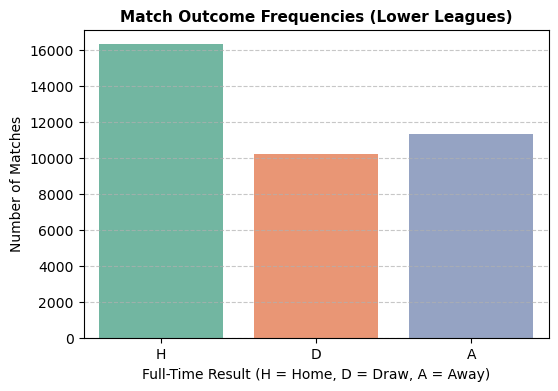

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load your Premier League test dataset
df_prem = pd.read_csv('football_train_data.csv')

# 1. Calculate percentage breakdown for Premier League outcomes
prem_counts = df_prem['FTR'].value_counts()
prem_percentages = df_prem['FTR'].value_counts(normalize=True) * 100

print("Lower League Counts:\n", prem_counts)
print("\nLower League Percentages:\n", prem_percentages.round(2))

# 2. Create and save a clean bar chart for your LaTeX report
plt.figure(figsize=(6, 4))
sns.countplot(x='FTR', data=df_prem, order=['H', 'D', 'A'], palette='Set2')

plt.title('Match Outcome Frequencies (Lower Leagues)', fontsize=11, fontweight='bold')
plt.xlabel('Full-Time Result (H = Home, D = Draw, A = Away)', fontsize=10)
plt.ylabel('Number of Matches', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Save high-res image for LaTeX report inclusion
plt.savefig('prem_outcome_frequencies.png', dpi=300, bbox_inches='tight')
plt.show()

Premier League Counts:
 H    3976
A    2605
D    2159
Name: FTR, dtype: int64

Premier League Percentages:
 H    45.49
A    29.81
D    24.70
Name: FTR, dtype: float64


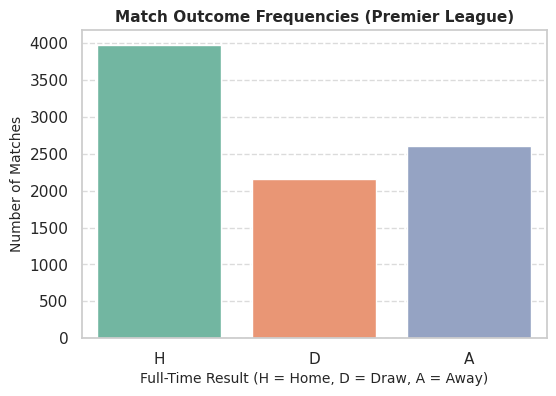

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load your Premier League test dataset
df_prem = pd.read_csv('football_test_data.csv')

# 1. Calculate percentage breakdown for Premier League outcomes
prem_counts = df_prem['FTR'].value_counts()
prem_percentages = df_prem['FTR'].value_counts(normalize=True) * 100

print("Premier League Counts:\n", prem_counts)
print("\nPremier League Percentages:\n", prem_percentages.round(2))

# 2. Create and save a clean bar chart for your LaTeX report
plt.figure(figsize=(6, 4))
sns.countplot(x='FTR', data=df_prem, order=['H', 'D', 'A'], palette='Set2')

plt.title('Match Outcome Frequencies (Premier League)', fontsize=11, fontweight='bold')
plt.xlabel('Full-Time Result (H = Home, D = Draw, A = Away)', fontsize=10)
plt.ylabel('Number of Matches', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Save high-res image for LaTeX report inclusion
plt.savefig('prem_outcome_frequencies.png', dpi=300, bbox_inches='tight')
plt.show()

In [11]:
import pandas as pd
from sklearn.metrics import accuracy_score

# 1. Ensure odds columns are strictly numeric (handle missing/string entries)
odds_cols = ['B365H', 'B365D', 'B365A']
for col in odds_cols:
    df_prem[col] = pd.to_numeric(df_prem[col], errors='coerce')

# Drop rows where any of the closing odds or target results are missing
df_clean = df_prem.dropna(subset=odds_cols + ['FTR']).copy()

# 2. Find the outcome with the lowest odds (highest implied probability)
min_odds_col = df_clean[odds_cols].idxmin(axis=1)
odds_pred_map = {'B365H': 'H', 'B365D': 'D', 'B365A': 'A'}
df_clean['Market_Prediction'] = min_odds_col.map(odds_pred_map)

# 3. Calculate Market Odds Baseline Accuracy
market_baseline_acc = accuracy_score(df_clean['FTR'], df_clean['Market_Prediction'])
print(f"Non-Naive Market Baseline Accuracy: {market_baseline_acc * 100:.2f}%")

Non-Naive Market Baseline Accuracy: 46.44%


In [13]:
# Count columns with zero missing values in your dataframe
clean_cols_count = (df.isnull().sum() == 0).sum()
print(f"Number of columns with no missing values: {clean_cols_count}")

Number of columns with no missing values: 16


In [14]:
# Extract and print columns with zero missing values
complete_columns = list(df.columns[df.isnull().sum() == 0])
print(complete_columns)

['FTR', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'B365H', 'B365D', 'B365A']
